---
## 0. Setup and imports

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    matthews_corrcoef, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# imblearn's Pipeline, not scikit-learn's: only this one applies a resampler,
# and only to the training part of each fold. sklearn's Pipeline ignores it.
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
TARGET = "Bankrupt?"
N_FOLDS = 5
DATA_PATH = "data/taiwanese_bankruptcy.csv"
EXPECTED_SHAPE = (6819, 95)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

In [2]:
def summarise_folds(fold_scores: list[dict]) -> dict:
    """[{'pr_auc': 0.4, ...}, ...] -> {'pr_auc': {'mean': .., 'std': ..}, ...}"""
    if not fold_scores:
        raise ValueError("no fold scores to summarise")
    return {
        k: {"mean": float(np.mean([f[k] for f in fold_scores])),
            "std":  float(np.std([f[k] for f in fold_scores]))}
        for k in fold_scores[0]
    }


REPORT_METRICS = ("pr_auc", "roc_auc", "precision", "recall", "f1", "mcc", "accuracy")


def results_row(name: str, summary: dict, metrics=REPORT_METRICS) -> dict:
    """One row of the comparison table: 'mean ± std' strings, in report order.

    Metric order is deliberate. PR-AUC leads because at a ~3% positive rate it
    is the only headline that cannot be gamed by predicting the majority class;
    accuracy comes last for the same reason.
    """
    row = {"model": name}
    for m in metrics:
        if m in summary:
            row[m] = f"{summary[m]['mean']:.3f} ± {summary[m]['std']:.3f}"
    return row

---
## 2. Loading the data

In [3]:
def load_data() -> tuple[pd.DataFrame, pd.Series]:
    """Load the raw dataset. No scaling, no selection, no splitting."""
    df = pd.read_csv(DATA_PATH)

    # The published file has a leading space on nearly every column name.
    df.columns = [c.strip() for c in df.columns]

    y = df[TARGET].astype(int)
    X = df.drop(columns=[TARGET])

    # Fail loudly if this is not the file we think it is.
    assert X.shape == EXPECTED_SHAPE, f"expected {EXPECTED_SHAPE}, got {X.shape}"
    assert y.isin([0, 1]).all(), "target is not binary"
    return X, y


X, y = load_data()
print(f"features: {X.shape}   target: {y.shape}")

features: (6819, 95)   target: (6819,)


## 3. Exploratory analysis

In [4]:
print(f"rows: {X.shape[0]}   features: {X.shape[1]}")
print(f"missing values: {int(X.isna().sum().sum())}")
print(f"duplicate rows: {int(X.duplicated().sum())}")

counts = y.value_counts().sort_index()
pct = (y.value_counts(normalize=True).sort_index() * 100).round(2)
balance = pd.DataFrame({"count": counts, "percent": pct})
balance.index = ["not bankrupt (0)", "bankrupt (1)"]
print()
print(balance)

minority = float(pct.loc[1])
majority = float(pct.loc[0])
print(f"\nminority class: {minority:.2f}%")
print(f"a model that always predicts 0 would score {majority:.2f}% accuracy")

rows: 6819   features: 95
missing values: 0
duplicate rows: 0

                  count  percent
not bankrupt (0)   6599    96.77
bankrupt (1)        220     3.23

minority class: 3.23%
a model that always predicts 0 would score 96.77% accuracy


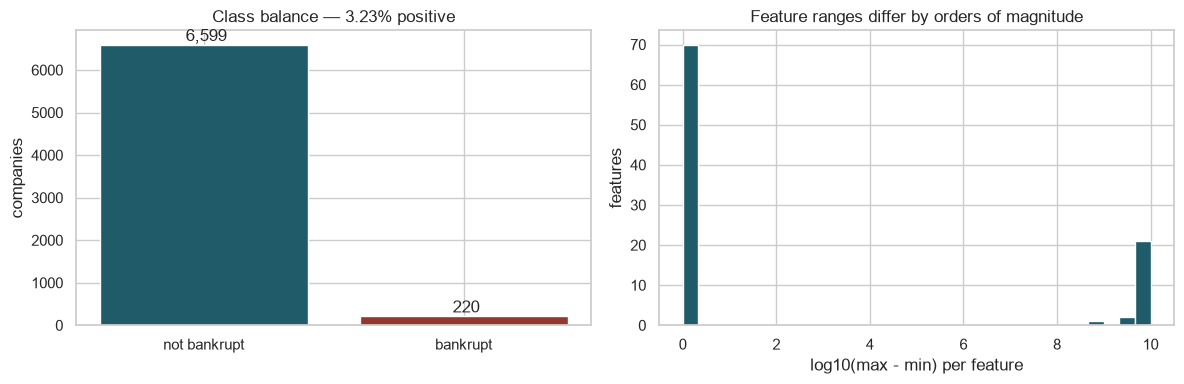

widest-range features:
Quick Asset Turnover Rate          1.000000e+10
Current Asset Turnover Rate        1.000000e+10
Cash Turnover Rate                 1.000000e+10
Operating Expense Rate             9.990000e+09
Fixed Assets Turnover Frequency    9.990000e+09

This spread is why the linear model needs standardisation (lecture 2).


In [5]:
# Distribution of the target, and a look at the scale spread across features.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(["not bankrupt", "bankrupt"], counts.values,
            color=["#1F5B68", "#93382F"])
axes[0].set_ylabel("companies")
axes[0].set_title(f"Class balance — {minority:.2f}% positive")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f" {v:,}", ha="center", va="bottom")

ranges = (X.max() - X.min()).sort_values(ascending=False)
axes[1].hist(np.log10(ranges.replace(0, np.nan).dropna()), bins=30,
             color="#1F5B68")
axes[1].set_xlabel("log10(max - min) per feature")
axes[1].set_ylabel("features")
axes[1].set_title("Feature ranges differ by orders of magnitude")
plt.tight_layout()
plt.show()

print("widest-range features:")
print(ranges.head(5).to_string())
print("\nThis spread is why the linear model needs standardisation (lecture 2).")

In [6]:
# Criterion 2 asks for the attributes described, not listed. Bucket the 95
# ratios by keyword so the report carries a table rather than 95 bullets.
GROUPS = {
    "Profitability": ["ROA", "profit", "margin", "income", "earning", "EPS",
                      "return"],
    "Leverage":      ["debt", "liabilit", "equity", "borrow", "interest-bearing",
                      "mortgage"],
    "Liquidity":     ["cash", "current ratio", "quick", "working capital"],
    "Efficiency":    ["turnover", "frequency", "rotation", "per share",
                      "expense rate"],
    "Growth":        ["growth rate", "increase"],
}


def bucket(col: str) -> str:
    low = col.lower()
    for name, keys in GROUPS.items():
        if any(k.lower() in low for k in keys):
            return name
    return "Other / structural"


attrs = pd.DataFrame({"attribute": X.columns})
attrs["group"] = attrs["attribute"].map(bucket)

summary = (attrs.groupby("group").size()
           .rename("n_features").sort_values(ascending=False)
           .to_frame())
summary["share"] = (summary["n_features"] / len(attrs) * 100).round(1)
print(summary)

print("\ntwo examples per group:")
for g, sub in attrs.groupby("group"):
    print(f"  {g}: {', '.join(sub['attribute'].head(2))}")

                    n_features  share
group                                
Profitability               25   26.3
Leverage                    23   24.2
Other / structural          19   20.0
Efficiency                  13   13.7
Liquidity                   13   13.7
Growth                       2    2.1

two examples per group:
  Efficiency: Operating Expense Rate, Research and development expense rate
  Growth: Total Asset Growth Rate, Net Value Growth Rate
  Leverage: Interest-bearing debt interest rate, Total debt/Total net worth
  Liquidity: Cash flow rate, Cash Flow Per Share
  Other / structural: Pre-tax net Interest Rate, After-tax net Interest Rate
  Profitability: ROA(C) before interest and depreciation before interest, ROA(A) before interest and % after tax


## 4. Correlation and redundancy

In [7]:
corr = X.corr(numeric_only=True).abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

pairs = (upper.stack()
         .rename("abs_r")
         .reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
         .sort_values("abs_r", ascending=False)
         .reset_index(drop=True))

print("most redundant feature pairs:")
print(pairs.head(10).to_string(index=False))
print(f"\npairs above |r| = 0.90: {int((pairs['abs_r'] > 0.90).sum())}")

most redundant feature pairs:
                          feature_a                        feature_b    abs_r
      Current Liabilities/Liability   Current Liability to Liability 1.000000
         Current Liabilities/Equity      Current Liability to Equity 1.000000
                       Debt ratio %                 Net worth/Assets 1.000000
             Operating Gross Margin            Gross Profit to Sales 1.000000
            Net Value Per Share (A)          Net Value Per Share (C) 0.999837
             Operating Gross Margin      Realized Sales Gross Margin 0.999518
        Realized Sales Gross Margin            Gross Profit to Sales 0.999518
            Net Value Per Share (B)          Net Value Per Share (A) 0.999342
            Net Value Per Share (B)          Net Value Per Share (C) 0.999179
Operating Profit Per Share (Yuan ¥) Operating profit/Paid-in capital 0.998696

pairs above |r| = 0.90: 28


In [8]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop one feature from every pair whose |Pearson r| exceeds threshold.

    A lecture-2 filter method, written as a transformer so the decision about
    which column to drop is made from training data only, inside each CV fold.
    Doing it once on the whole dataset would leak information about the
    validation rows into the choice of features.
    """

    def __init__(self, threshold: float = 0.90):
        self.threshold = threshold

    def fit(self, X, y=None):
        Xdf = pd.DataFrame(X)

        # Zero-variance columns go first. This dataset has exactly one -
        # "Net Income Flag" is 1 for all 6,819 rows - and it carries no
        # information, leaves an all-NaN row in the correlation matrix, and
        # makes the ANOVA F-test undefined (0/0).
        self.constant_ = [c for c in Xdf.columns if Xdf[c].nunique(dropna=False) <= 1]
        Xdf = Xdf.drop(columns=self.constant_)

        c = Xdf.corr(numeric_only=True).abs()
        up = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))
        self.dropped_ = [col for col in up.columns
                         if (up[col] > self.threshold).any()]
        self.keep_ = [col for col in Xdf.columns if col not in self.dropped_]
        self.n_features_in_ = pd.DataFrame(X).shape[1]
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.keep_].to_numpy()

    def get_feature_names_out(self, input_features=None):
        # Lets the pipeline carry real ratio names through to section 7's
        # coefficients. Without this the interpretation is impossible.
        return np.asarray(self.keep_, dtype=object)


# What each threshold would cost us, before committing to one.
sweep = []
for t in [0.80, 0.85, 0.90, 0.95, 0.99]:
    f = CorrelationFilter(threshold=t).fit(X)
    sweep.append({"threshold": t, "dropped": len(f.dropped_),
                  "kept": len(f.keep_)})
print(pd.DataFrame(sweep).to_string(index=False))

 threshold  dropped  kept
      0.80       25    69
      0.85       22    72
      0.90       19    75
      0.95       16    78
      0.99       10    84


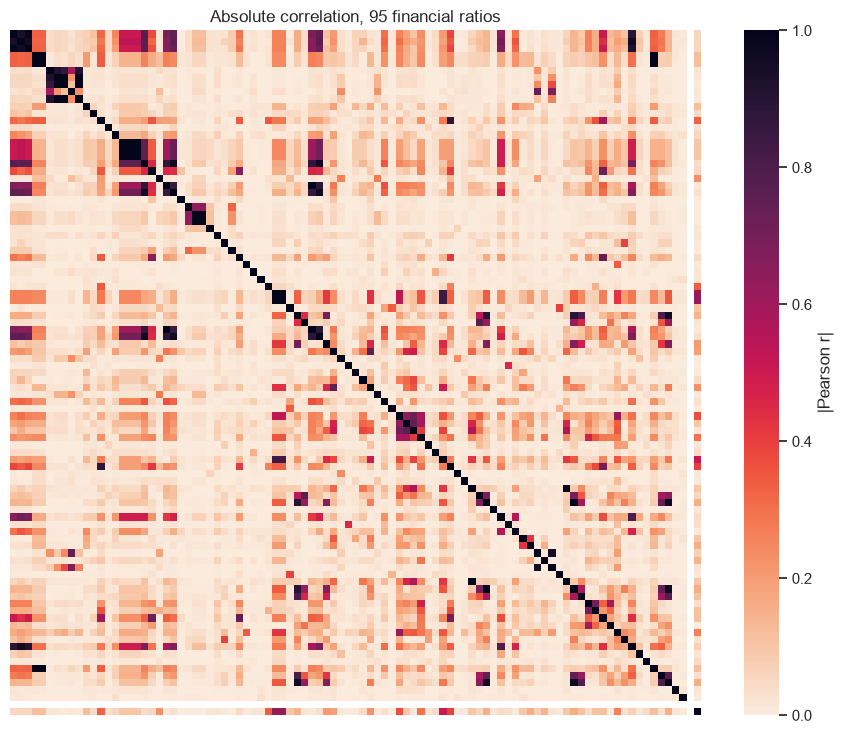

at |r| > 0.9: dropping 19 of 95, keeping 75

examples of dropped columns:
  ROA(A) before interest and % after tax
  ROA(B) before interest and depreciation after tax
  Realized Sales Gross Margin
  Pre-tax net Interest Rate
  After-tax net Interest Rate
  Continuous interest rate (after tax)
  Net Value Per Share (A)
  Net Value Per Share (C)


In [9]:
CORR_THRESHOLD = 0.90   # chosen from the sweep above; justified in the report

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="rocket_r", xticklabels=False, yticklabels=False,
            ax=ax, cbar_kws={"label": "|Pearson r|"}, vmin=0, vmax=1)
ax.set_title(f"Absolute correlation, {X.shape[1]} financial ratios")
plt.tight_layout()
plt.show()

chosen = CorrelationFilter(threshold=CORR_THRESHOLD).fit(X)
print(f"at |r| > {CORR_THRESHOLD}: dropping {len(chosen.dropped_)} of "
      f"{X.shape[1]}, keeping {len(chosen.keep_)}")
print("\nexamples of dropped columns:")
print("  " + "\n  ".join(chosen.dropped_[:8]))

## 5. The preprocessing pipeline

In [10]:
class Preprocessor(BaseEstimator, TransformerMixin):
    """Correlation filter -> univariate ranking -> standardisation, as ONE
    estimator rather than a nested Pipeline.

    Why not a Pipeline: imbalanced-learn refuses to accept a Pipeline as an
    intermediate step of another pipeline ("All intermediate steps of the
    chain should not be Pipelines"), and evaluate() has to slot this in front
    of an optional resampler. One estimator sidesteps that entirely and keeps
    `named_steps["pre"]` and `get_feature_names_out()` working.

    Stays UNFITTED until evaluate()/tune() clone and fit it inside each fold.
    Fitting it once outside would leak validation statistics into training -
    the failure on lecture 7's "Evaluation Leakage" slide.
    """

    def __init__(self, corr_threshold: float = CORR_THRESHOLD,
                 k: int = 25, score_func=f_classif):
        self.corr_threshold = corr_threshold
        self.k = k
        self.score_func = score_func

    def fit(self, X, y=None):
        self.filter_ = CorrelationFilter(threshold=self.corr_threshold).fit(X, y)
        Xf = self.filter_.transform(X)
        # Clamp k: after dropping constant and collinear columns there may be
        # fewer than k left, and asking for more just warns and returns all.
        self.k_used_ = min(self.k, Xf.shape[1])
        self.select_ = SelectKBest(score_func=self.score_func,
                                   k=self.k_used_).fit(Xf, y)
        self.scale_ = StandardScaler().fit(self.select_.transform(Xf))
        self.n_features_in_ = pd.DataFrame(X).shape[1]
        return self

    def transform(self, X):
        Xf = self.filter_.transform(X)
        return self.scale_.transform(self.select_.transform(Xf))

    def get_feature_names_out(self, input_features=None):
        # Carries real ratio names through to section 7's coefficients.
        return self.select_.get_feature_names_out(
            self.filter_.get_feature_names_out())


def build_preprocessor(corr_threshold: float = CORR_THRESHOLD,
                       k: int = 25,
                       score_func=f_classif) -> BaseEstimator:
    """Unfitted preprocessor. Tune its `k` as `pre__k`."""
    return Preprocessor(corr_threshold=corr_threshold, k=k,
                        score_func=score_func)


def tune(model, preprocessor, X, y, param_grid, resampler=None):
    """Grid search the WHOLE pipeline, scored by PR-AUC.

    Searching the pipeline rather than the bare estimator means the
    preprocessing is refitted for every candidate inside every fold, so there
    is no leakage, and it lets k be tuned alongside the model's own
    hyperparameters.
    """
    steps = [("pre", clone(preprocessor))]
    if resampler is not None:
        steps.append(("resample", clone(resampler)))
    steps.append(("clf", clone(model)))

    gs = GridSearchCV(
        ImbPipeline(steps),
        param_grid,
        scoring="average_precision",      # PR-AUC. Never accuracy.
        cv=StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1,
        refit=True,
    )
    return gs.fit(X, y)


pre = build_preprocessor()
pre

,corr_threshold,0.9
,k,25
,score_func,<function f_c...t 0x11514d7a0>


---
## 6. The evaluation harness

In [11]:
def evaluate(model, preprocessor, X, y, resampler=None, threshold=0.5) -> dict:
    """Stratified N_FOLDS-fold CV. Returns mean and std for every metric."""
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True,
                          random_state=RANDOM_STATE)
    fold_scores, mats, curves = [], [], []

    for tr, va in skf.split(X, y):
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]

        # Rule 1: preprocessor fitted on the training part only.
        # Rule 2: resampler inside the pipeline, so it also sees training only.
        steps = [("pre", clone(preprocessor))]
        if resampler is not None:
            steps.append(("resample", clone(resampler)))
        steps.append(("clf", clone(model)))

        pipe = ImbPipeline(steps).fit(X_tr, y_tr)

        proba = pipe.predict_proba(X_va)[:, 1]
        pred = (proba >= threshold).astype(int)

        fold_scores.append({
            "pr_auc":    average_precision_score(y_va, proba),
            "roc_auc":   roc_auc_score(y_va, proba),
            "precision": precision_score(y_va, pred, zero_division=0),
            "recall":    recall_score(y_va, pred, zero_division=0),
            "f1":        f1_score(y_va, pred, zero_division=0),
            "mcc":       matthews_corrcoef(y_va, pred),
            "accuracy":  accuracy_score(y_va, pred),
        })
        mats.append(confusion_matrix(y_va, pred, labels=[0, 1]))
        p, r, _ = precision_recall_curve(y_va, proba)
        fpr, tpr, _ = roc_curve(y_va, proba)
        curves.append({"pr": (r, p), "roc": (fpr, tpr)})

    out = summarise_folds(fold_scores)
    out["confusion_matrix"] = np.sum(mats, axis=0)
    out["curves"] = curves
    return out


def show_confusion(summary: dict, label: str) -> pd.DataFrame:
    """Confusion matrix summed across folds, as a labelled frame."""
    cm = pd.DataFrame(summary["confusion_matrix"],
                      index=["actual: healthy", "actual: bankrupt"],
                      columns=["predicted: healthy", "predicted: bankrupt"])
    print(f"{label} — confusion matrix, summed over {N_FOLDS} folds")
    return cm

## 7. Logistic Regression

In [12]:
def make_logreg() -> BaseEstimator:
    """Linear arm. class_weight is what makes it see the ~3% minority."""
    return LogisticRegression(
        # L2 is the default. Passing penalty= explicitly is deprecated from
        # scikit-learn 1.8 and removed in 1.10, so we leave it alone.
        class_weight="balanced",
        max_iter=5000,          # 95 scaled features converge slowly
        random_state=RANDOM_STATE,
    )


LOGREG_GRID = {
    "clf__C":         [0.01, 0.1, 1.0, 10.0],
    "pre__k":         [15, 25, 40],
}

logreg_gs = tune(make_logreg(), pre, X, y, LOGREG_GRID)

print("best params:", logreg_gs.best_params_)
print(f"best cross-validated PR-AUC: {logreg_gs.best_score_:.4f}")

best params: {'clf__C': 1.0, 'pre__k': 15}
best cross-validated PR-AUC: 0.3865


In [13]:
logreg_best = logreg_gs.best_estimator_
logreg_summary = evaluate(logreg_best.named_steps["clf"],
                          logreg_best.named_steps["pre"], X, y)

print(pd.DataFrame([results_row("Logistic Regression", logreg_summary)])
      .to_string(index=False))
print()
show_confusion(logreg_summary, "Logistic Regression")

              model        pr_auc       roc_auc     precision        recall            f1           mcc      accuracy
Logistic Regression 0.384 ± 0.036 0.932 ± 0.020 0.169 ± 0.012 0.832 ± 0.110 0.281 ± 0.021 0.336 ± 0.038 0.863 ± 0.011

Logistic Regression — confusion matrix, summed over 5 folds


,predicted: healthy,predicted: bankrupt
actual: healthy,5702,897
actual: bankrupt,37,183


top 12 by magnitude (positive = pushes toward bankruptcy):
                                                  ratio  coefficient
                             Current Liabilities/Equity    -2.866083
                                   Borrowing dependency     2.145952
                Persistent EPS in the Last Four Seasons    -1.763942
                                 Working Capital/Equity    -1.340600
                    Operating Profit Per Share (Yuan ¥)     1.042616
                                           Debt ratio %     0.889944
ROA(C) before interest and depreciation before interest    -0.829847
                            Current Liability to Assets     0.735407
                     Net Income to Stockholder's Equity    -0.340589
                                Net Value Per Share (B)    -0.299190
                                  Liability-Assets Flag     0.272881
                    Current Liability to Current Assets    -0.206012


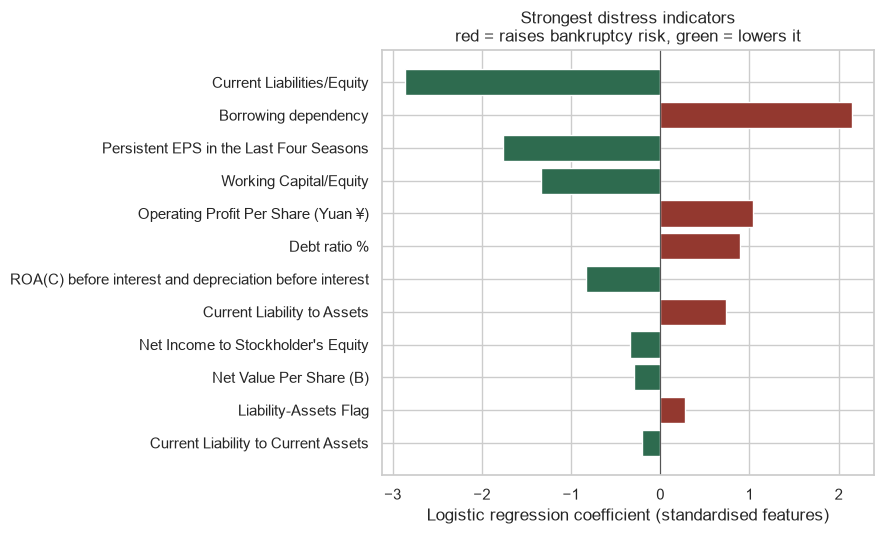

In [14]:
# Which ratios signal distress. Features are standardised, so coefficient
# magnitudes are directly comparable and the sign gives the direction.
names = logreg_best.named_steps["pre"].get_feature_names_out()
coefs = logreg_best.named_steps["clf"].coef_[0]

imp = (pd.DataFrame({"ratio": names, "coefficient": coefs})
       .assign(abs_coef=lambda d: d["coefficient"].abs())
       .sort_values("abs_coef", ascending=False)
       .drop(columns="abs_coef")
       .reset_index(drop=True))

print("top 12 by magnitude (positive = pushes toward bankruptcy):")
print(imp.head(12).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
top = imp.head(12).iloc[::-1]
ax.barh(top["ratio"], top["coefficient"],
        color=["#93382F" if c > 0 else "#2E6B4F" for c in top["coefficient"]])
ax.axvline(0, color="#555", lw=.8)
ax.set_xlabel("Logistic regression coefficient (standardised features)")
ax.set_title("Strongest distress indicators\nred = raises bankruptcy risk, green = lowers it")
plt.tight_layout()
plt.show()

---
## 8. Random Forest

In [15]:
def make_rf() -> BaseEstimator:
    """Ensemble arm. n_jobs=1 so GridSearchCV owns the parallelism."""
    return RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        n_jobs=1,
        random_state=RANDOM_STATE,
    )


RF_GRID = {
    "clf__max_depth":        [None, 8, 16],
    "clf__min_samples_leaf": [1, 5, 20],
    "pre__k":                [15, 25, 40],
}

rf_gs = tune(make_rf(), pre, X, y, RF_GRID)

print("best params:", rf_gs.best_params_)
print(f"best cross-validated PR-AUC: {rf_gs.best_score_:.4f}")

best params: {'clf__max_depth': 16, 'clf__min_samples_leaf': 5, 'pre__k': 40}
best cross-validated PR-AUC: 0.4204


In [16]:
rf_best = rf_gs.best_estimator_
rf_summary = evaluate(rf_best.named_steps["clf"],
                      rf_best.named_steps["pre"], X, y)

print(pd.DataFrame([results_row("Random Forest", rf_summary)])
      .to_string(index=False))
print()
show_confusion(rf_summary, "Random Forest")

        model        pr_auc       roc_auc     precision        recall            f1           mcc      accuracy
Random Forest 0.420 ± 0.063 0.936 ± 0.024 0.326 ± 0.032 0.636 ± 0.077 0.429 ± 0.032 0.430 ± 0.036 0.945 ± 0.007

Random Forest — confusion matrix, summed over 5 folds


,predicted: healthy,predicted: bankrupt
actual: healthy,6305,294
actual: bankrupt,80,140


In [17]:
# Permutation importance on the ORIGINAL columns: permute a raw ratio and let
# the pipeline re-transform. More interpretable than permuting post-selection
# features, and it avoids the bias of impurity-based feature_importances_
# toward high-cardinality variables.
X_tr, X_va, y_tr, y_va = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

rf_fitted = clone(rf_best).fit(X_tr, y_tr)

perm = permutation_importance(
    rf_fitted, X_va, y_va, scoring="average_precision",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

rf_imp = (pd.DataFrame({"ratio": X.columns,
                        "drop_in_pr_auc": perm.importances_mean,
                        "std": perm.importances_std})
          .sort_values("drop_in_pr_auc", ascending=False)
          .reset_index(drop=True))
print("top 12 by drop in PR-AUC when permuted:")
print(rf_imp.head(12).to_string(index=False))

top 12 by drop in PR-AUC when permuted:
                                                  ratio  drop_in_pr_auc      std
                Persistent EPS in the Last Four Seasons        0.055826 0.038870
                                   Borrowing dependency        0.040166 0.022517
ROA(C) before interest and depreciation before interest        0.033778 0.028662
                                 Cash Flow to Liability        0.030940 0.022922
                              Cash Flow to Total Assets        0.025133 0.017450
                                      Cash/Total Assets        0.022420 0.007856
                                    Equity to Liability        0.019932 0.017437
                      Retained Earnings to Total Assets        0.018685 0.031344
                                Total Asset Growth Rate        0.015344 0.018608
                                           Debt ratio %        0.011551 0.015291
                            Operating profit per person        0.0112

## 10. Class imbalance study

In [18]:
STRATEGIES = {
    "none":          (None,       None),
    "class weights": ("balanced", None),
    "SMOTE":         (None,       SMOTE(random_state=RANDOM_STATE)),
    "undersample":   (None,       RandomUnderSampler(random_state=RANDOM_STATE)),
}

MODEL_FACTORIES = {
    "Logistic Regression": lambda w: LogisticRegression(
        class_weight=w, max_iter=5000,
        random_state=RANDOM_STATE),
    # Fewer trees here than in section 8: this is 40 fits, and the comparison
    # between strategies is unaffected by the exact forest size.
    "Random Forest": lambda w: RandomForestClassifier(
        n_estimators=200, class_weight=w, n_jobs=-1,
        random_state=RANDOM_STATE),
}

rows = []
for strategy, (weight, resampler) in STRATEGIES.items():
    for model_name, factory in MODEL_FACTORIES.items():
        res = evaluate(factory(weight), build_preprocessor(), X, y,
                       resampler=resampler)
        # results_row() also returns a "model" key, so build the row from it
        # and then set the identifying columns — not the other way round.
        row = results_row(model_name, res)
        row["strategy"] = strategy
        rows.append(row)

imbalance_table = (pd.DataFrame(rows)[
    ["model", "strategy", "pr_auc", "recall", "precision", "f1", "accuracy"]]
    .sort_values(["model", "strategy"])
    .reset_index(drop=True))
print(imbalance_table.to_string(index=False))

              model      strategy        pr_auc        recall     precision            f1      accuracy
Logistic Regression         SMOTE 0.376 ± 0.036 0.805 ± 0.086 0.171 ± 0.007 0.282 ± 0.014 0.868 ± 0.008
Logistic Regression class weights 0.383 ± 0.035 0.818 ± 0.091 0.166 ± 0.007 0.276 ± 0.015 0.862 ± 0.008
Logistic Regression          none 0.382 ± 0.029 0.191 ± 0.059 0.513 ± 0.068 0.272 ± 0.060 0.968 ± 0.001
Logistic Regression   undersample 0.344 ± 0.026 0.836 ± 0.090 0.163 ± 0.010 0.273 ± 0.018 0.856 ± 0.011
      Random Forest         SMOTE 0.382 ± 0.047 0.536 ± 0.059 0.335 ± 0.020 0.411 ± 0.027 0.951 ± 0.003
      Random Forest class weights 0.396 ± 0.059 0.382 ± 0.033 0.445 ± 0.072 0.409 ± 0.044 0.964 ± 0.004
      Random Forest          none 0.401 ± 0.061 0.168 ± 0.034 0.566 ± 0.103 0.257 ± 0.045 0.969 ± 0.002
      Random Forest   undersample 0.354 ± 0.043 0.868 ± 0.097 0.162 ± 0.008 0.272 ± 0.011 0.850 ± 0.017


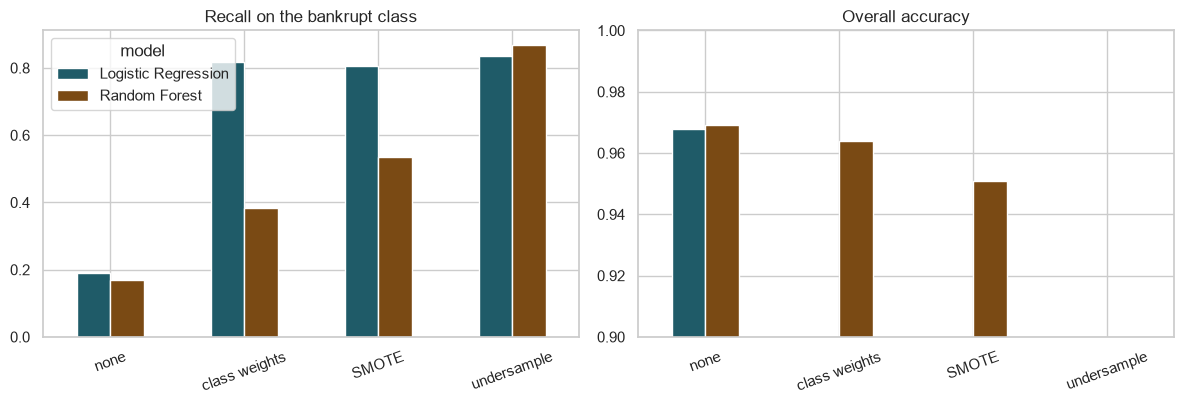

Note the right-hand axis starts at 0.90 — accuracy is almost flat.


In [19]:
# Accuracy hardly moves; recall does. Shown rather than asserted.
plot_df = pd.DataFrame(rows)
plot_df["recall_mean"] = plot_df["recall"].str.split(" ").str[0].astype(float)
plot_df["accuracy_mean"] = plot_df["accuracy"].str.split(" ").str[0].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, metric, title in [(axes[0], "recall_mean", "Recall on the bankrupt class"),
                          (axes[1], "accuracy_mean", "Overall accuracy")]:
    wide = plot_df.pivot(index="strategy", columns="model", values=metric)
    wide = wide.reindex(list(STRATEGIES))
    wide.plot(kind="bar", ax=ax, color=["#1F5B68", "#7A4A14"], rot=20,
              legend=(metric == "recall_mean"))
    ax.set_title(title)
    ax.set_xlabel("")
axes[1].set_ylim(0.9, 1.0)
plt.tight_layout()
plt.show()
print("Note the right-hand axis starts at 0.90 — accuracy is almost flat.")